# Beta Diversity Bray Curtis PCoA Visualizations

The goal of this script is to calculate Bray Curtis between sample Distance and visualize the obtained results usind a PCoA.


In [8]:
import os
import pandas as pd
import qiime2 as q2
from qiime2 import Visualization
from skbio import OrdinationResults
from seaborn import scatterplot
import matplotlib.pyplot as plt
import seaborn as sns


%matplotlib inline

%cd /home/jovyan/MicroOdyssey_clean

pcoa_dir="output/04_diversityanalyses"
data_dir="data"
result_dir="output/04_diversityanalyses"

/home/jovyan/MicroOdyssey_clean


In [9]:
# Load Bray–Curtis PCoA
pcoa = q2.Artifact.load(f"{pcoa_dir}/bray_curtis_pcoa_results.qza").view(OrdinationResults)

# Get sample coordinates
coords = pcoa.samples.iloc[:, :2].copy()
coords.columns = ["PC1", "PC2"]

# Load metadata
meta = pd.read_csv(
    f"{data_dir}/metadata.tsv",
    sep="\t",
    index_col=0)

# Combine coordinates with infant age
df_pcoa = coords.join(meta[["age_months"]]).dropna()

In [10]:
print("Samples included:", len(df_pcoa))
display(df_pcoa.head())

Samples included: 228


,PC1,PC2,age_months
SRR25052449,0.032948,0.331561,24.0
SRR25052450,-0.384933,-0.046253,12.0
SRR25052451,0.133895,-0.018618,6.0
SRR25052452,-0.047512,-0.110301,2.0
SRR25052453,-0.512772,-0.288261,0.0


#### Plot the PCoA 

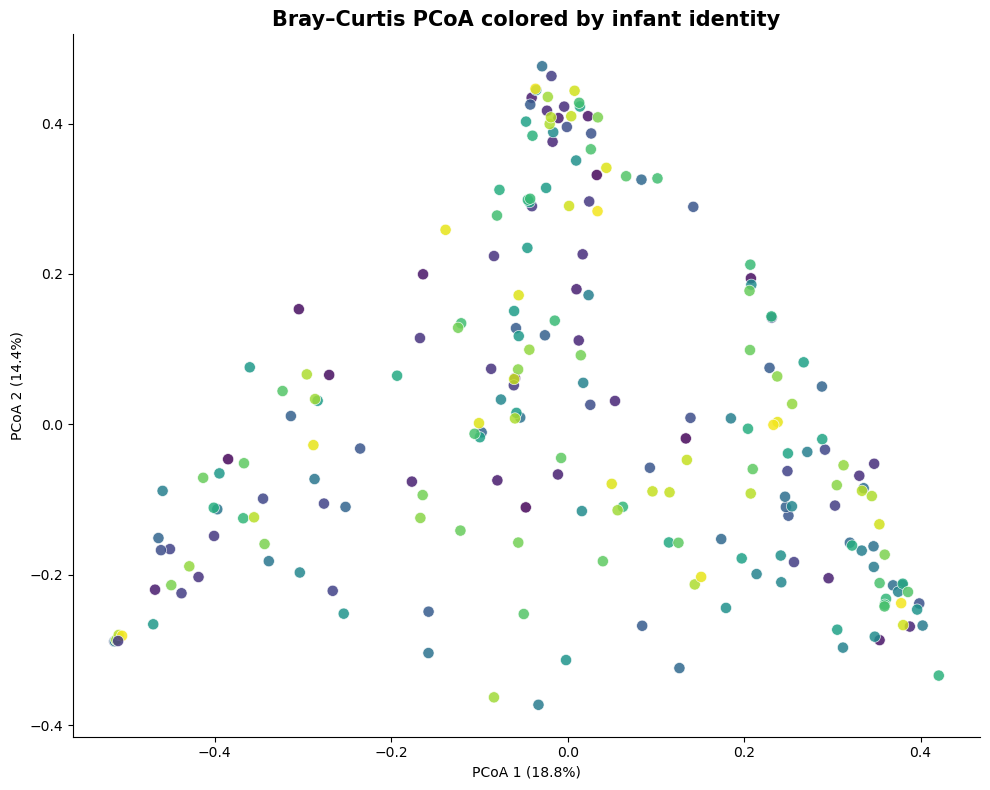

In [12]:
df_pcoa["host_id"] = meta.loc[df_pcoa.index, "host_id"].astype(str)

%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 8))

sns.scatterplot(
    data=df_pcoa,
    x="PC1",
    y="PC2",
    hue="host_id", #color the data points by host_id
    palette="viridis",
    s=65,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
    legend=False,
    ax=ax
)

pc1 = pcoa.proportion_explained.iloc[0] * 100
pc2 = pcoa.proportion_explained.iloc[1] * 100

ax.set_xlabel(f"PCoA 1 ({pc1:.1f}%)")
ax.set_ylabel(f"PCoA 2 ({pc2:.1f}%)")
ax.set_title(
    "Bray–Curtis PCoA colored by infant identity",
    fontsize=15,
    weight="bold"
)

sns.despine()
plt.tight_layout()

plt.savefig(
    f"{result_dir}/figures/bray_curtis_pcoa_host_id.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

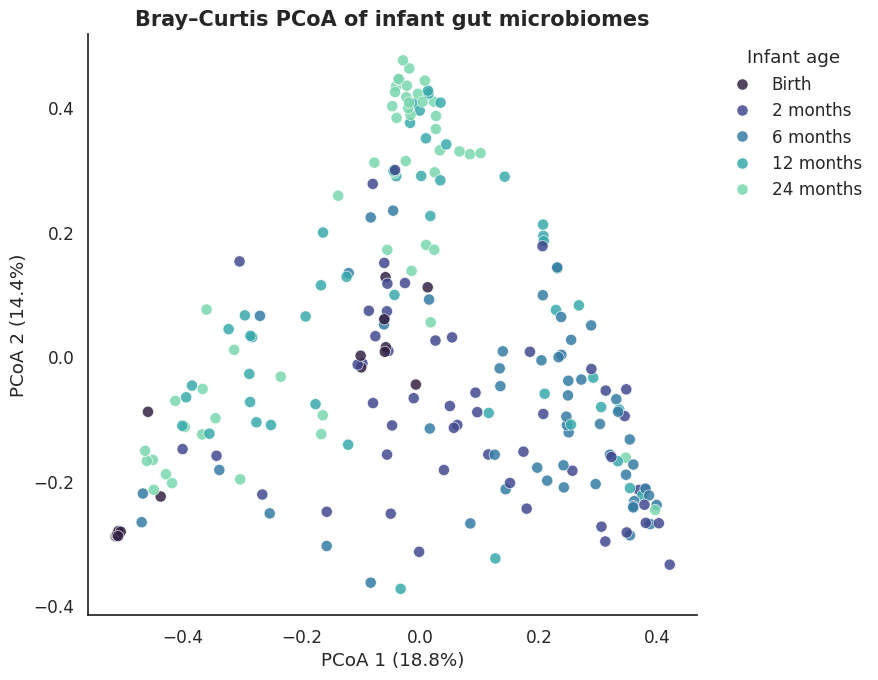

In [13]:
#re-order the age, save it as new variable: order
df_pcoa["Age"] = df_pcoa["age_months"].astype(int).map({
    0: "Birth",
    2: "2 months",
    6: "6 months",
    12: "12 months",
    24: "24 months"
})

order = ["Birth", "2 months", "6 months", "12 months", "24 months"]

#for visualization
sns.set_theme(style="white", font_scale=1.1)

fig, ax = plt.subplots(figsize=(9, 7))

#make scatterplot
sns.scatterplot(
    data=df_pcoa,
    x="PC1",
    y="PC2",
    hue="Age", #color the data points by age
    hue_order=order,
    palette=sns.color_palette("mako", n_colors=5),
    s=65,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Percentage of variation represented by the first two axes
pc1 = pcoa.proportion_explained.iloc[0] * 100
pc2 = pcoa.proportion_explained.iloc[1] * 100

ax.set_xlabel(f"PCoA 1 ({pc1:.1f}%)")
ax.set_ylabel(f"PCoA 2 ({pc2:.1f}%)")
ax.set_title(
    "Bray–Curtis PCoA of infant gut microbiomes",
    fontsize=15,
    weight="bold"
)

ax.legend(
    title="Infant age",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine()
plt.tight_layout()

# Save BEFORE showing otherwise it doesnt work
plt.savefig(
    f"{result_dir}/figures/bray_curtis_pcoa_age.png",
    dpi=300,
    bbox_inches="tight"
)

#plt.savefig(
   # f"{results_dir}/bray_curtis_pcoa_age.svg",
  #  bbox_inches="tight"
#)

plt.show()

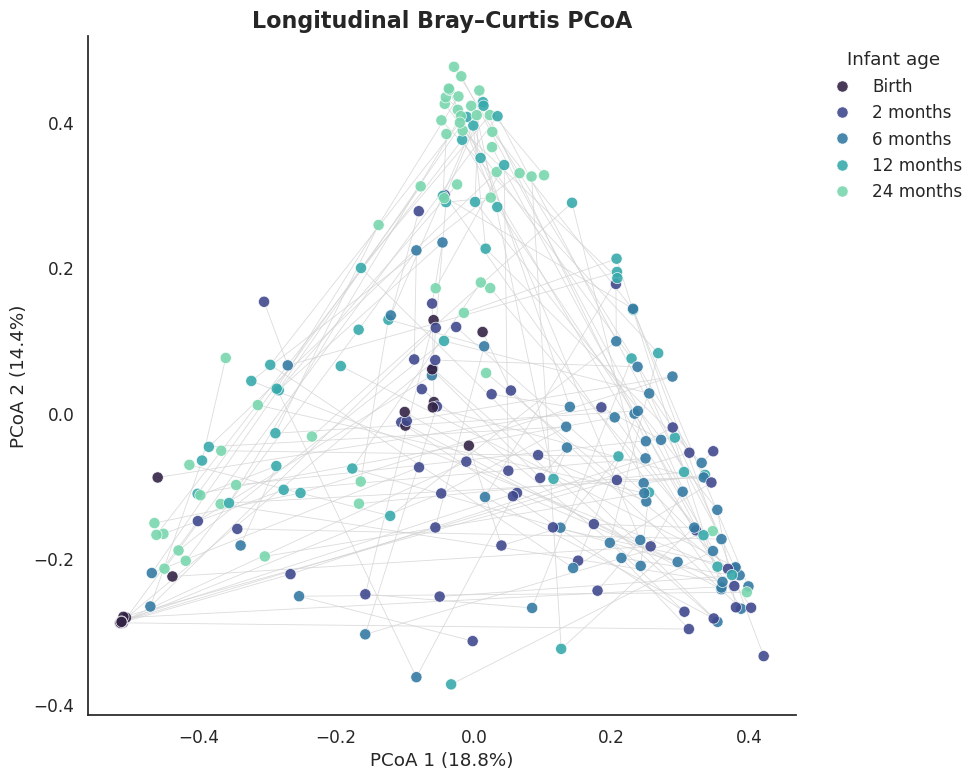

In [14]:
#connect samples belonging to the same infant with lines
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

# Add infant identity
df_pcoa["host_id"] = meta.loc[df_pcoa.index, "host_id"].astype(str)

# Sort samples by age within each infant
df_pcoa = df_pcoa.sort_values(["host_id", "age_months"])

sns.set_theme(style="white", font_scale=1.1)

fig, ax = plt.subplots(figsize=(10, 8))

# Connect samples from each infant in chronological order
for infant, group in df_pcoa.groupby("host_id"):
    ax.plot(
        group["PC1"],
        group["PC2"],
        color="lightgray",
        linewidth=0.6,
        alpha=0.8,
        zorder=1
    )

# Color points by sampling age
sns.scatterplot(
    data=df_pcoa,
    x="PC1",
    y="PC2",
    hue="Age",
    hue_order=["Birth", "2 months", "6 months", "12 months", "24 months"],
    palette=sns.color_palette("mako", n_colors=5),
    s=65,
    alpha=0.9,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    zorder=2
)

# Add percentage of variation explained
pc1 = pcoa.proportion_explained.iloc[0] * 100
pc2 = pcoa.proportion_explained.iloc[1] * 100

ax.set_xlabel(f"PCoA 1 ({pc1:.1f}%)")
ax.set_ylabel(f"PCoA 2 ({pc2:.1f}%)")

ax.set_title(
    "Longitudinal Bray–Curtis PCoA",
    fontsize=16,
    weight="bold"
)

ax.legend(
    title="Infant age",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine()
plt.tight_layout()

# Save before displaying
plt.savefig(
    f"{result_dir}/figures/bray_curtis_pcoa_trajectories.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig("bray_PCoA.png", dpi=300, bbox_inches="tight")

plt.show()

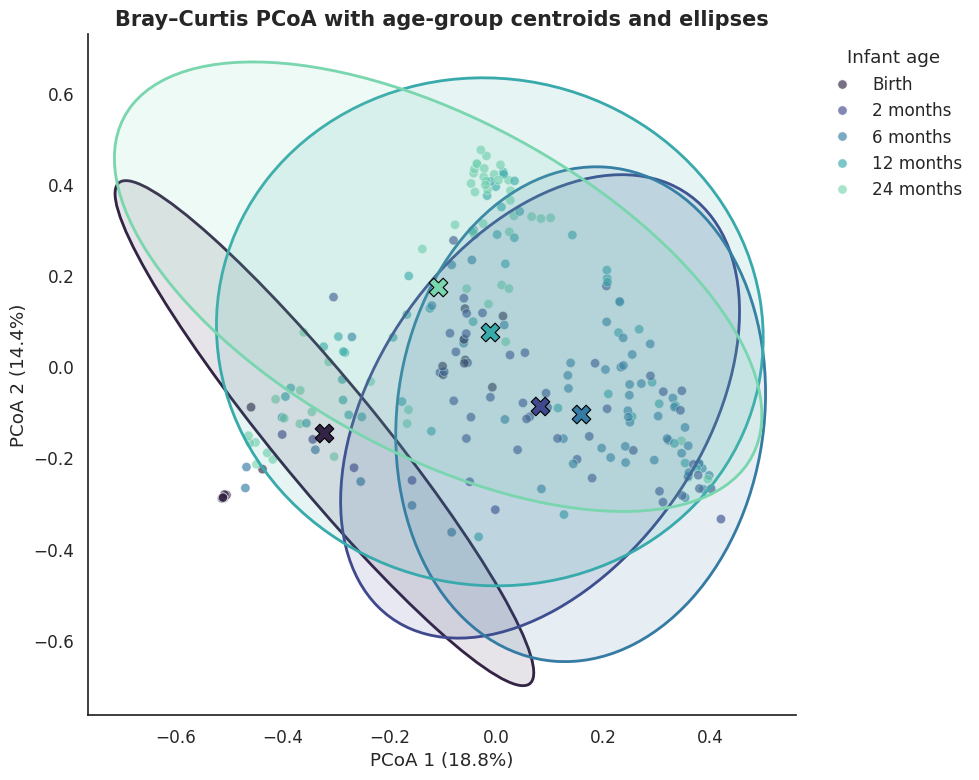

In [15]:
import numpy as np
from matplotlib.patches import Ellipse

order = ["Birth", "2 months", "6 months", "12 months", "24 months"]
colors = dict(zip(order, sns.color_palette("mako", 5)))

fig, ax = plt.subplots(figsize=(10, 8))

# Plot individual samples
sns.scatterplot(
    data=df_pcoa,
    x="PC1",
    y="PC2",
    hue="Age",
    hue_order=order,
    palette=colors,
    s=45,
    alpha=0.65,
    edgecolor="white",
    ax=ax
)

# Add centroids and 95% dispersion ellipses
for age in order:
    group = df_pcoa[df_pcoa["Age"] == age]
    points = group[["PC1", "PC2"]].dropna().to_numpy()

    if len(points) < 3:
        continue

    centroid = points.mean(axis=0)
    covariance = np.cov(points, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    angle = np.degrees(np.arctan2(
        eigenvectors[1, 1], eigenvectors[0, 1]
    ))

    # 95% normal-theory dispersion ellipse
    width, height = 2 * np.sqrt(5.991 * eigenvalues)

    ellipse = Ellipse(
        xy=centroid,
        width=width,
        height=height,
        angle=angle,
        facecolor=colors[age],
        edgecolor=colors[age],
        alpha=0.12,
        linewidth=2
    )

    ax.add_patch(ellipse)

    # Ellipse outline
    ax.add_patch(Ellipse(
        xy=centroid,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        edgecolor=colors[age],
        linewidth=2
    ))

    # Centroid
    ax.scatter(
        centroid[0],
        centroid[1],
        marker="X",
        s=180,
        color=colors[age],
        edgecolor="black",
        linewidth=0.8,
        zorder=5
    )

pc1 = pcoa.proportion_explained.iloc[0] * 100
pc2 = pcoa.proportion_explained.iloc[1] * 100

ax.set_xlabel(f"PCoA 1 ({pc1:.1f}%)")
ax.set_ylabel(f"PCoA 2 ({pc2:.1f}%)")
ax.set_title(
    "Bray–Curtis PCoA with age-group centroids and ellipses",
    fontsize=15,
    weight="bold"
)

ax.legend(
    title="Infant age",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.savefig(
    f"{result_dir}/figures/bray_pcoa_centroids_ellipses.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()